# 02 - Entraînement : classification des maladies de plantes

Objectif : entraîner un classifieur d'images par transfer learning (ResNet18 pré-entraîné sur ImageNet).

Ce qu'on fait dans ce notebook :
1. Chargement du dataset et split train / val / test (stratifié)
2. Transforms (augmentation sur le train, resize simple sur val/test)
3. Gestion du déséquilibre de classes (loss pondérée)
4. Définition du modèle (ResNet18 via `timm`)
5. Boucle d'entraînement avec suivi loss/accuracy
6. Évaluation finale sur le test set (rapport de classification + matrice de confusion)
7. Sauvegarde du modèle pour la suite (déploiement)


In [1]:
# Si besoin, décommente pour installer les dépendances manquantes
# !pip install torch torchvision timm scikit-learn seaborn tqdm

import random
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

import timm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

# Reproductibilité
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Device : GPU si dispo, sinon CPU (MPS pour Mac Apple Silicon)
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Device utilisé : {device}")

c:\Users\clement\anaconda3\envs\safe1\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device utilisé : cpu


## 1. Chargement du dataset et split train / val / test

In [2]:
DATA_DIR = Path("../Plant_sickness/PlantVillage")  # adapte si besoin
assert DATA_DIR.exists(), f"Dossier introuvable : {DATA_DIR.resolve()}"

# On charge une première fois sans transform juste pour récupérer les classes et labels
base_dataset = datasets.ImageFolder(DATA_DIR)
classes = base_dataset.classes
n_classes = len(classes)
print(f"Nombre de classes : {n_classes}")

targets = [label for _, label in base_dataset.samples]

# Split stratifié : 70% train / 15% val / 15% test
train_idx, temp_idx = train_test_split(
    range(len(targets)), test_size=0.3, stratify=targets, random_state=SEED
)
temp_targets = [targets[i] for i in temp_idx]
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.5, stratify=temp_targets, random_state=SEED
)

print(f"Train : {len(train_idx)} images")
print(f"Val   : {len(val_idx)} images")
print(f"Test  : {len(test_idx)} images")

Nombre de classes : 15
Train : 14446 images
Val   : 3096 images
Test  : 3096 images


## 2. Transforms

- **Train** : augmentation légère cohérente avec des photos de feuilles (flip horizontal, petite rotation,
  léger jitter de couleur) — on évite les transformations trop agressives qui dénatureraient les symptômes
  visuels des maladies (taches, décolorations).
- **Val / Test** : resize simple, pas d'augmentation (on veut évaluer sur des données représentatives du réel).

In [3]:
IMG_SIZE = 224  # taille standard attendue par les modèles pré-entraînés ImageNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# On recrée un ImageFolder par type de transform, puis on découpe avec Subset
# (permet d'avoir des transforms différents sur train vs val/test avec les mêmes indices)
train_dataset_full = datasets.ImageFolder(DATA_DIR, transform=train_transform)
eval_dataset_full = datasets.ImageFolder(DATA_DIR, transform=eval_transform)

train_dataset = Subset(train_dataset_full, train_idx)
val_dataset = Subset(eval_dataset_full, val_idx)
test_dataset = Subset(eval_dataset_full, test_idx)

BATCH_SIZE = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

## 3. Gestion du déséquilibre de classes

On calcule des poids inversement proportionnels à la fréquence de chaque classe dans le train set,
et on les passe à la loss (`CrossEntropyLoss`). Les classes rares (ex: Potato_healthy) pèseront
plus lourd dans l'erreur, ce qui pousse le modèle à ne pas les négliger.

In [4]:
train_targets = [targets[i] for i in train_idx]

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(n_classes),
    y=train_targets,
)
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

for c, w in zip(classes, class_weights.cpu().numpy()):
    print(f"{c:45s} poids = {w:.2f}")

Pepper__bell___Bacterial_spot                 poids = 1.38
Pepper__bell___healthy                        poids = 0.93
Potato___Early_blight                         poids = 1.38
Potato___Late_blight                          poids = 1.38
Potato___healthy                              poids = 9.09
Tomato_Bacterial_spot                         poids = 0.65
Tomato_Early_blight                           poids = 1.38
Tomato_Late_blight                            poids = 0.72
Tomato_Leaf_Mold                              poids = 1.45
Tomato_Septoria_leaf_spot                     poids = 0.78
Tomato_Spider_mites_Two_spotted_spider_mite   poids = 0.82
Tomato__Target_Spot                           poids = 0.98
Tomato__Tomato_YellowLeaf__Curl_Virus         poids = 0.43
Tomato__Tomato_mosaic_virus                   poids = 3.69
Tomato_healthy                                poids = 0.86


## 4. Le modèle

ResNet18 pré-entraîné sur ImageNet, avec la dernière couche remplacée pour nos `n_classes`.
C'est un bon compromis : suffisamment puissant, rapide à entraîner même sur CPU/GPU modeste,
et largement documenté (facile à justifier ce choix en entretien).

In [5]:
model = timm.create_model("resnet18", pretrained=True, num_classes=n_classes)
model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Nombre de paramètres entraînables : {n_params:,}")

Nombre de paramètres entraînables : 11,184,207


c:\Users\clement\anaconda3\envs\safe1\Lib\site-packages\huggingface_hub\file_download.py:141: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\clement\.cache\huggingface\hub\models--timm--resnet18.a1_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


## 5. Boucle d'entraînement

In [6]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss, total_correct, total_samples = 0.0, 0, 0

    context = torch.enable_grad() if is_train else torch.no_grad()
    with context:
        for images, labels in tqdm(loader, leave=False):
            images, labels = images.to(device), labels.to(device)

            if is_train:
                optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            if is_train:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            total_correct += (preds == labels).sum().item()
            total_samples += images.size(0)

    return total_loss / total_samples, total_correct / total_samples

In [7]:
N_EPOCHS = 10
best_val_acc = 0.0
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)
BEST_MODEL_PATH = MODEL_DIR / "best_model.pth"

for epoch in range(1, N_EPOCHS + 1):
    train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc = run_epoch(model, val_loader, criterion, optimizer=None)

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"Epoch {epoch:2d}/{N_EPOCHS} | "
          f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
          f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({
            "model_state_dict": model.state_dict(),
            "classes": classes,
            "img_size": IMG_SIZE,
        }, BEST_MODEL_PATH)
        print(f"  -> Nouveau meilleur modèle sauvegardé (val_acc={val_acc:.4f})")

print(f"\nMeilleure accuracy validation : {best_val_acc:.4f}")

Epoch  1/10 | train_loss=1.6459 train_acc=0.6338 | val_loss=0.4848 val_acc=0.9037
  -> Nouveau meilleur modèle sauvegardé (val_acc=0.9037)


Epoch  2/10 | train_loss=0.3575 train_acc=0.9097 | val_loss=0.1574 val_acc=0.9554
  -> Nouveau meilleur modèle sauvegardé (val_acc=0.9554)


Epoch  3/10 | train_loss=0.1778 train_acc=0.9525 | val_loss=0.1050 val_acc=0.9687
  -> Nouveau meilleur modèle sauvegardé (val_acc=0.9687)


Epoch  4/10 | train_loss=0.1266 train_acc=0.9639 | val_loss=0.0620 val_acc=0.9822
  -> Nouveau meilleur modèle sauvegardé (val_acc=0.9822)


Epoch  5/10 | train_loss=0.0935 train_acc=0.9725 | val_loss=0.0451 val_acc=0.9897
  -> Nouveau meilleur modèle sauvegardé (val_acc=0.9897)


Epoch  6/10 | train_loss=0.0664 train_acc=0.9787 | val_loss=0.0425 val_acc=0.9884


Epoch  7/10 | train_loss=0.0537 train_acc=0.9855 | val_loss=0.0335 val_acc=0.9900
  -> Nouveau meilleur modèle sauvegardé (val_acc=0.9900)


Epoch  8/10 | train_loss=0.0454 train_acc=0.9868 | val_loss=0.0273 val_acc=0.9916
  -> Nouveau meilleur modèle sauvegardé (val_acc=0.9916)


Epoch  9/10 | train_loss=0.0394 train_acc=0.9886 | val_loss=0.0251 val_acc=0.9929
  -> Nouveau meilleur modèle sauvegardé (val_acc=0.9929)


Epoch 10/10 | train_loss=0.0323 train_acc=0.9903 | val_loss=0.0226 val_acc=0.9926

Meilleure accuracy validation : 0.9929


## 6. Courbes d'apprentissage

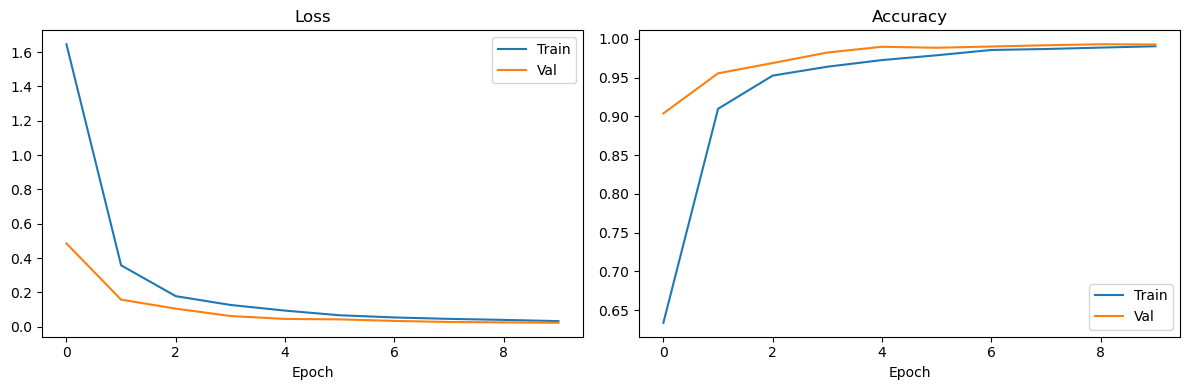

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_loss"], label="Train")
axes[0].plot(history["val_loss"], label="Val")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history["train_acc"], label="Train")
axes[1].plot(history["val_acc"], label="Val")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

## 7. Évaluation finale sur le test set

On recharge le **meilleur** modèle sauvegardé (celui avec la meilleure val_acc, pas forcément
le dernier de la boucle) et on l'évalue sur le test set, qu'il n'a jamais vu.

In [9]:
checkpoint = torch.load(BEST_MODEL_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in tqdm(test_loader):
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=classes, zero_division=0))

100%|██████████| 97/97 [00:36<00:00,  2.64it/s]


                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.98      1.00      0.99       149
                     Pepper__bell___healthy       1.00      1.00      1.00       221
                      Potato___Early_blight       0.99      0.99      0.99       150
                       Potato___Late_blight       0.99      0.99      0.99       150
                           Potato___healthy       0.96      1.00      0.98        23
                      Tomato_Bacterial_spot       0.99      1.00      1.00       319
                        Tomato_Early_blight       0.97      0.95      0.96       150
                         Tomato_Late_blight       0.99      0.97      0.98       287
                           Tomato_Leaf_Mold       0.99      1.00      0.99       143
                  Tomato_Septoria_leaf_spot       0.99      0.99      0.99       266
Tomato_Spider_mites_Two_spotted_spider_mite       1.00      0.99

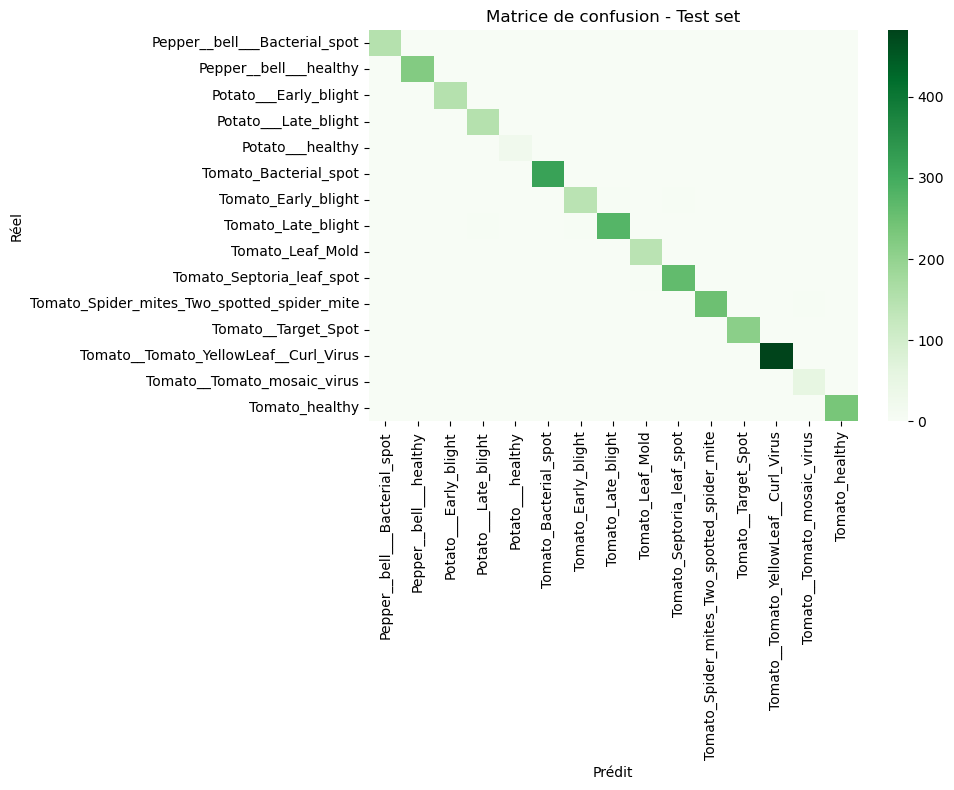

In [10]:
cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=False, cmap="Greens", xticklabels=classes, yticklabels=classes, ax=ax)
ax.set_xlabel("Prédit")
ax.set_ylabel("Réel")
ax.set_title("Matrice de confusion - Test set")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Résumé et prochaines étapes

À compléter après exécution :
- Accuracy finale sur le test set
- Classes où le modèle se trompe le plus (regarder la matrice de confusion — souvent des maladies
  visuellement proches, ex: différents types de "spot" sur tomate)
- Le modèle est sauvegardé dans `../models/best_model.pth`, prêt à être chargé pour l'inférence

**Prochaine étape : notebook `03_predict.ipynb` ou `app/app.py`** — construire une interface Gradio
qui charge ce modèle et permet d'uploader une photo pour obtenir une prédiction en direct.
